In [ ]:
from google.colab import files
uploade=files.upload()

Saving transactions.xlsx to transactions.xlsx


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
df = pd.read_excel("/content/transactions.xlsx")

BASE_DIR = Path("/content/transactions.xlsx").resolve().parent
EXCEL_FILE = BASE_DIR / "transactions.xlsx"

print(df.head())
print(EXCEL_FILE)

   Transaction_ID Customer_ID  Balance  Interest_Rate     Product_Type  \
0            1001        C001    36500            5.0     Term Deposit   
1            1002        C002    50000            4.5  Savings Account   
2            1003        C003    12000            3.5     Term Deposit   
3            1004        C004    85000            5.2  Current Account   
4            1005        C005    25000            4.0     Term Deposit   

  Account_Creation_Timestamp Transaction_Date  Transaction_Amount  
0        2026-01-01 09:15:00       2026-01-03               12000  
1        2025-12-20 12:00:00       2026-01-08                8500  
2        2026-01-15 10:30:00       2026-01-15               22000  
3        2026-02-01 14:20:00       2026-01-22                6000  
4        2026-03-31 16:45:00       2026-01-28               15000  
/content/transactions.xlsx


In [ ]:
print(df.head)

<bound method NDFrame.head of     Transaction_ID Customer_ID  Balance  Interest_Rate     Product_Type  \
0             1001        C001    36500            5.0     Term Deposit   
1             1002        C002    50000            4.5  Savings Account   
2             1003        C003    12000            3.5     Term Deposit   
3             1004        C004    85000            5.2  Current Account   
4             1005        C005    25000            4.0     Term Deposit   
5             1006        C006    42000            4.8  Savings Account   
6             1007        C007    18000            3.0     Term Deposit   
7             1008        C008    63000            5.0     Term Deposit   
8             1009        C009    30000            4.2  Current Account   
9             1010        C010    95000            5.5  Savings Account   
10            1011        C011    15000            3.8     Term Deposit   
11            1012        C012    72000            4.9  Savings Accoun

In [ ]:
print(df.columns.tolist())

['Transaction_ID', 'Customer_ID', 'Balance', 'Interest_Rate', 'Product_Type', 'Account_Creation_Timestamp', 'Transaction_Date', 'Transaction_Amount']


In [ ]:
df["Balance"] = pd.to_numeric(df["Balance"], errors="coerce")
df["Interest_Rate"] = pd.to_numeric(df["Interest_Rate"], errors="coerce")

df["Interest_Accrued"] = (
    df["Balance"].to_numpy()
    * (df["Interest_Rate"].to_numpy() / 365)
)


In [ ]:
print(df[["Customer_ID", "Balance", "Interest_Rate", "Interest_Accrued"]].head())


  Customer_ID  Balance  Interest_Rate  Interest_Accrued
0        C001    36500            5.0        500.000000
1        C002    50000            4.5        616.438356
2        C003    12000            3.5        115.068493
3        C004    85000            5.2       1210.958904
4        C005    25000            4.0        273.972603


In [ ]:
df["Account_Creation_Timestamp"] = pd.to_datetime(
    df["Account_Creation_Timestamp"], errors="coerce"
)
rollout_date = pd.Timestamp("2026-01-01")
end_date = rollout_date + pd.Timedelta(days=90)

term_deposit_clients = df[
    df["Product_Type"].astype("string").str.strip().str.lower().eq("term deposit")
    & df["Account_Creation_Timestamp"].ge(rollout_date)
    & df["Account_Creation_Timestamp"].lt(end_date)
].copy()

In [ ]:
print("\nTerm Deposit clients within the 90-day window:")
print(term_deposit_clients[[
    "Customer_ID", "Product_Type", "Account_Creation_Timestamp", "Balance"
]])
term_deposit_clients.to_csv(
    BASE_DIR / "term_deposit_clients_90_days.csv", index=False
)
df["Transaction_Date"] = pd.to_datetime(
    df["Transaction_Date"], errors="coerce"
)
df["Transaction_Amount"] = pd.to_numeric(
    df["Transaction_Amount"], errors="coerce"
)
valid_transactions = df.dropna(
    subset=["Transaction_Date", "Transaction_Amount"]
).copy()
monthly_totals = (
    valid_transactions
    .set_index("Transaction_Date")["Transaction_Amount"]
    .resample("MS")
    .sum()
)
monthly_totals.index.name = "Month"
monthly_totals.name = "Monthly_Transaction_Total"
print("Monthly transaction totals:")
print(monthly_totals)
monthly_totals.to_csv(BASE_DIR / "monthly_transaction_totals.csv")
monthly_growth_pct = monthly_totals.pct_change() * 100
print("Month-on-month growth (%):")
print(monthly_growth_pct.round(2))


Term Deposit clients within the 90-day window:
   Customer_ID  Product_Type Account_Creation_Timestamp  Balance
0         C001  Term Deposit        2026-01-01 09:15:00    36500
2         C003  Term Deposit        2026-01-15 10:30:00    12000
4         C005  Term Deposit        2026-03-31 16:45:00    25000
7         C008  Term Deposit        2026-02-18 11:10:00    63000
10        C011  Term Deposit        2026-02-25 15:15:00    15000
12        C013  Term Deposit        2026-01-28 09:40:00    28000
15        C016  Term Deposit        2026-03-20 10:50:00    67000
17        C018  Term Deposit        2026-03-29 14:00:00    44000
Monthly transaction totals:
Month
2026-01-01     63500
2026-02-01     72000
2026-03-01     95000
2026-04-01    123000
Freq: MS, Name: Monthly_Transaction_Total, dtype: int64
Month-on-month growth (%):
Month
2026-01-01      NaN
2026-02-01    13.39
2026-03-01    31.94
2026-04-01    29.47
Freq: MS, Name: Monthly_Transaction_Total, dtype: float64


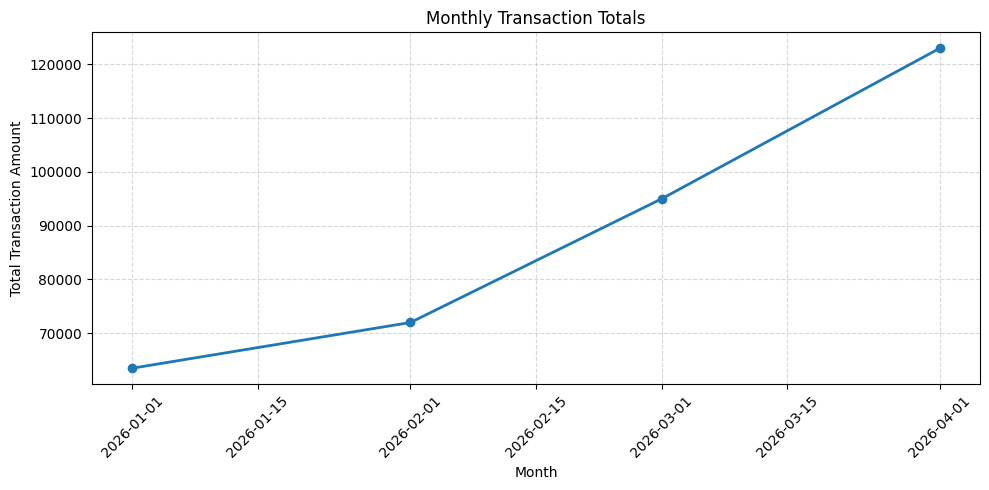

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_totals.index,
    monthly_totals.values,
    marker="o",
    linewidth=2
)
plt.title("Monthly Transaction Totals")
plt.xlabel("Month")
plt.ylabel("Total Transaction Amount")
plt.grid(True, linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    BASE_DIR / "monthly_transaction_growth.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
df.to_excel(BASE_DIR / "processed_transactions.xlsx", index=False)